In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from sklearn.preprocessing import OneHotEncoder,MinMaxScaler,StandardScaler

In [2]:
df=pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")

In [3]:
df.head()

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
0,Ultra Face Mask,Drunk Elephant,Blush,Weekly,67.85,1.4,686,30ml,Sensitive,Female,Tube,Retinol,False,Australia
1,Ultra Lipstick,Laura Mercier,Makeup Remover,Occasional,116.43,4.2,5483,250ml,Dry,Unisex,Bottle,Shea Butter,False,UK
2,Ultra Serum,Natasha Denona,Highlighter,Daily,90.84,1.6,5039,100ml,Sensitive,Male,Compact,Aloe Vera,True,Italy
3,Divine Serum,Ilia Beauty,Face Mask,Occasional,55.17,3.2,6202,250ml,Normal,Male,Tube,Glycerin,True,South Korea
4,Super Foundation,Charlotte Tilbury,Highlighter,Occasional,140.56,1.7,297,100ml,Oily,Female,Compact,Glycerin,False,Germany


In [7]:
df.tail()

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
14995,Magic Eyeliner,Patrick Ta,Face Mask,Daily,131.64,2.8,1470,250ml,Sensitive,Unisex,Tube,Aloe Vera,True,Italy
14996,Perfect Powder,Farsali,Serum,Weekly,76.35,2.1,7652,250ml,Dry,Unisex,Jar,Salicylic Acid,True,USA
14997,Magic Serum,Kiehl’s,Highlighter,Occasional,65.37,4.2,811,30ml,Combination,Unisex,Jar,Shea Butter,False,South Korea
14998,Magic Mascara,Perricone MD,Powder,Weekly,59.93,4.8,5482,250ml,Dry,Male,Jar,Aloe Vera,True,USA
14999,Divine Lip Liner,Tatcha,Blush,Daily,36.96,1.1,5452,200ml,Normal,Female,Bottle,Shea Butter,False,UK


In [79]:
df.shape

(15000, 58)

In [80]:
df.info

<bound method DataFrame.info of            Product_Name        Category Usage_Frequency  Price_USD    Rating  \
0       ultra face mask           blush          weekly  -0.304050 -1.371867   
1        ultra lipstick  makeup remover      occasional   0.898377  1.025414   
2           ultra serum     highlighter           daily   0.264987 -1.200632   
3          divine serum       face mask      occasional  -0.617898  0.169242   
4      super foundation     highlighter      occasional   1.495630 -1.115015   
...                 ...             ...             ...        ...       ...   
14995    magic eyeliner       face mask           daily   1.274847 -0.173226   
14996    perfect powder           serum          weekly  -0.093662 -0.772547   
14997       magic serum     highlighter      occasional  -0.365433  1.025414   
14998     magic mascara          powder          weekly  -0.500081  1.539117   
14999  divine lip liner           blush           daily  -1.068623 -1.628718   

       

In [21]:
df.columns

Index(['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD',
       'Rating', 'Number_of_Reviews', 'Product_Size', 'Skin_Type',
       'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free',
       'Country_of_Origin'],
      dtype='str')

In [11]:
df.dtypes

Product_Name             str
Brand                    str
Category                 str
Usage_Frequency          str
Price_USD            float64
Rating               float64
Number_of_Reviews      int64
Product_Size             str
Skin_Type                str
Gender_Target            str
Packaging_Type           str
Main_Ingredient          str
Cruelty_Free            bool
Country_of_Origin        str
dtype: object

In [28]:
print("Number of unique values")
df.nunique()

Number of unique values


Product_Name          120
Brand                  40
Category               24
Usage_Frequency         4
Price_USD            9204
Rating                 41
Number_of_Reviews    7734
Product_Size            6
Skin_Type               5
Gender_Target           3
Packaging_Type          6
Main_Ingredient         7
Cruelty_Free            2
Country_of_Origin       8
dtype: int64

In [16]:
df.describe()

,Price_USD,Rating,Number_of_Reviews
count,15000.000000,15000.000000,15000.000000
mean,80.134108,3.002327,5014.231333
std,40.402983,1.168029,2855.665464
min,10.000000,1.000000,52.000000
25%,45.480000,2.000000,2562.000000
50%,80.040000,3.000000,5002.000000
75%,114.760000,4.000000,7497.000000
max,149.990000,5.000000,10000.000000


In [18]:
df.describe(include='str')

,Product_Name,Brand,Category,Usage_Frequency,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Country_of_Origin
count,15000,15000,15000,15000,15000,15000,15000,15000,15000,15000
unique,120,40,24,4,6,5,3,6,7,8
top,Super Setting Spray,Milk Makeup,Serum,Occasional,100ml,Combination,Male,Jar,Retinol,Italy
freq,154,426,710,3794,2551,3060,5017,2567,2180,1942


In [19]:
df.describe(include='all')

,Product_Name,Brand,Category,Usage_Frequency,Price_USD,Rating,Number_of_Reviews,Product_Size,Skin_Type,Gender_Target,Packaging_Type,Main_Ingredient,Cruelty_Free,Country_of_Origin
count,15000,15000,15000,15000,15000.000000,15000.000000,15000.000000,15000,15000,15000,15000,15000,15000,15000
unique,120,40,24,4,NaN,NaN,NaN,6,5,3,6,7,2,8
top,Super Setting Spray,Milk Makeup,Serum,Occasional,NaN,NaN,NaN,100ml,Combination,Male,Jar,Retinol,False,Italy
freq,154,426,710,3794,NaN,NaN,NaN,2551,3060,5017,2567,2180,7592,1942
mean,NaN,NaN,NaN,NaN,80.134108,3.002327,5014.231333,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,40.402983,1.168029,2855.665464,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,10.000000,1.000000,52.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,45.480000,2.000000,2562.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,80.040000,3.000000,5002.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,114.760000,4.000000,7497.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
print("Number of null elements")
df.isnull().sum()

Number of null elements


Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64

In [30]:
print("Null elements percentage:")
(df.isnull().sum()/len(df))*100

Null elements percentage:


Product_Name         0.0
Brand                0.0
Category             0.0
Usage_Frequency      0.0
Price_USD            0.0
Rating               0.0
Number_of_Reviews    0.0
Product_Size         0.0
Skin_Type            0.0
Gender_Target        0.0
Packaging_Type       0.0
Main_Ingredient      0.0
Cruelty_Free         0.0
Country_of_Origin    0.0
dtype: float64

In [31]:
print("Number of duplicated data")
df.duplicated().sum()
# if any duplicates us drop function as df.drop_duplicates(inplace=True)

Number of duplicated data


np.int64(0)

In [34]:
for col in df.select_dtypes(include=['str','category']).columns:
  print(f"\n{col}:\n",df[col].value_counts())


Product_Name:
 Product_Name
Super Setting Spray     154
Magic Face Oil          151
Magic Lip Liner         149
Perfect Lip Liner       147
Divine Exfoliator       146
                       ... 
Ultra Makeup Remover    103
Super Bronzer           102
Ultra Primer            101
Magic Exfoliator         96
Magic Moisturizer        93
Name: count, Length: 120, dtype: int64

Brand:
 Brand
Milk Makeup                426
Make Up For Ever           414
Kiehl’s                    411
NARS                       400
E.l.f.                     399
Farsali                    399
Yves Saint Laurent         394
Sisley                     392
Bite Beauty                392
Morphe                     392
KVD Beauty                 391
Glossier                   388
Becca                      388
Huda Beauty                384
RMS Beauty                 382
Bobby Brown                380
Ilia Beauty                379
Clinique                   377
Rare Beauty                375
Tatcha              

In [40]:
invalid_price = df[df['Price_USD'] < 0]
invalid_rating = df[(df['Rating'] < 1) | (df['Rating'] > 5)]

print("Invalid Prices:", len(invalid_price))
print("Invalid Ratings:", len(invalid_rating))

Invalid Prices: 0
Invalid Ratings: 0


In [41]:
if (df['Price_USD'] < 0).any():
    print("Negative prices found")
else:
    print("No negative prices")
if ((df['Rating'] < 1) | (df['Rating'] > 5)).any():
    print("Invalid ratings found")
else:
    print("All ratings are valid")

No negative prices
All ratings are valid


In [42]:
invalid_data = df[
    (df['Price_USD'] < 0) |
    (df['Rating'] < 1) |
    (df['Rating'] > 5)]
print(invalid_data)

Empty DataFrame
Columns: [Product_Name, Brand, Category, Usage_Frequency, Price_USD, Rating, Number_of_Reviews, Product_Size, Skin_Type, Gender_Target, Packaging_Type, Main_Ingredient, Cruelty_Free, Country_of_Origin]
Index: []


In [43]:
print(df[['Price_USD', 'Rating']].isnull().sum())

Price_USD    0
Rating       0
dtype: int64


In [45]:
# In our present dataset we don't usually have any missing or null values. If there exists a missing values we can adapt the methods below to handle it effectively.

numerical = df.select_dtypes(include=np.number).columns
categorical = df.select_dtypes(
    include=['str', 'category']).columns
# Record missing values before handling
before = df.isnull().sum()
for col in numerical:
    df[col] = df[col].fillna(df[col].median())
# Categorical imputation using mode
for col in categorical:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])
# Check missing values after handling
after = df.isnull().sum()
print("Missing values before:\n", before)
print("\nMissing values after:\n", after)
print("\nTotal values imputed:", before.sum() - after.sum())

Missing values before:
 Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64

Missing values after:
 Product_Name         0
Brand                0
Category             0
Usage_Frequency      0
Price_USD            0
Rating               0
Number_of_Reviews    0
Product_Size         0
Skin_Type            0
Gender_Target        0
Packaging_Type       0
Main_Ingredient      0
Cruelty_Free         0
Country_of_Origin    0
dtype: int64

Total values imputed: 0


In [46]:
summary = pd.DataFrame({
    'Missing Before': before,
    'Missing After': after,
    'Values Imputed': before - after})
print(summary)

                   Missing Before  Missing After  Values Imputed
Product_Name                    0              0               0
Brand                           0              0               0
Category                        0              0               0
Usage_Frequency                 0              0               0
Price_USD                       0              0               0
Rating                          0              0               0
Number_of_Reviews               0              0               0
Product_Size                    0              0               0
Skin_Type                       0              0               0
Gender_Target                   0              0               0
Packaging_Type                  0              0               0
Main_Ingredient                 0              0               0
Cruelty_Free                    0              0               0
Country_of_Origin               0              0               0


In [50]:
# IQR method implementation

def detect_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[column] < lower)|(data[column] > upper)]
    print(f"\nColumn: {column}")
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)
    print("Outlier Count:", len(outliers))
    return outliers

price_outliers = detect_outliers(df, 'Price_USD')
rating_outliers = detect_outliers(df, 'Rating')
review_outliers = detect_outliers(df, 'Number_of_Reviews')


Column: Price_USD
Lower Limit: -58.440000000000005
Upper Limit: 218.68
Outlier Count: 0

Column: Rating
Lower Limit: -1.0
Upper Limit: 7.0
Outlier Count: 0

Column: Number_of_Reviews
Lower Limit: -4840.5
Upper Limit: 14899.5
Outlier Count: 0


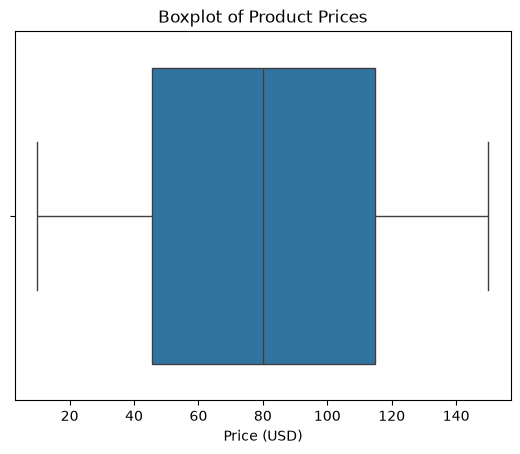

In [55]:
sns.boxplot(x=df['Price_USD'])
plt.title("Boxplot of Product Prices")
plt.xlabel("Price (USD)")
plt.show()

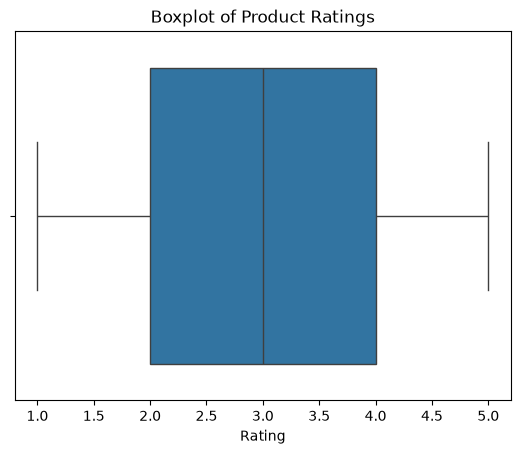

In [52]:
sns.boxplot(x=df['Rating'])
plt.title("Boxplot of Product Ratings")
plt.xlabel("Rating")
plt.show()

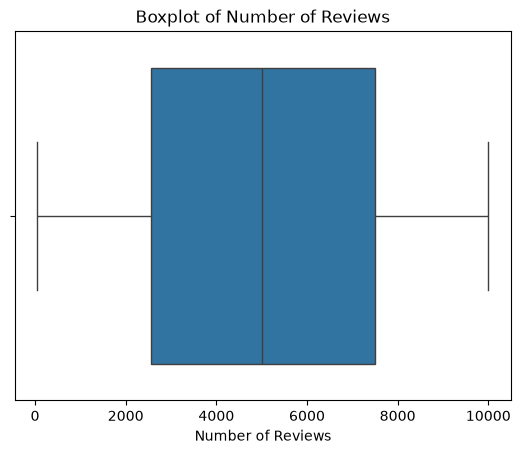

In [53]:
sns.boxplot(x=df['Number_of_Reviews'])
plt.title("Boxplot of Number of Reviews")
plt.xlabel("Number of Reviews")
plt.show()

In [56]:
mean = np.mean(df['Price_USD'])
std = np.std(df['Price_USD'])
z_score = (df['Price_USD'] - mean) / std
outliers = df[np.abs(z_score) > 3]
print(outliers)
print("Number of outliers:", len(outliers))

Empty DataFrame
Columns: [Product_Name, Brand, Category, Usage_Frequency, Price_USD, Rating, Number_of_Reviews, Product_Size, Skin_Type, Gender_Target, Packaging_Type, Main_Ingredient, Cruelty_Free, Country_of_Origin]
Index: []
Number of outliers: 0


In [67]:
df['Price_Zscore'] = zscore(df['Price_USD'])
outliers = df[np.abs(df['Price_Zscore']) > 3]

In [68]:
df.columns = df.columns.str.strip()

In [69]:
print(df.columns.tolist())

['Product_Name', 'Brand', 'Category', 'Usage_Frequency', 'Price_USD', 'Rating', 'Number_of_Reviews', 'Product_Size', 'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free', 'Country_of_Origin', 'Price_Zscore', 'Skin_Type_combination', 'Skin_Type_dry', 'Skin_Type_normal', 'Skin_Type_oily', 'Skin_Type_sensitive']


In [70]:
print([col for col in df.columns if 'skin' in col.lower()])

['Skin_Type_combination', 'Skin_Type_dry', 'Skin_Type_normal', 'Skin_Type_oily', 'Skin_Type_sensitive']


In [72]:
for col in df.columns:
    if 'Skin_Type' in col:
        print(col)
        print(df[col].unique())
print(df['Brand'].unique())

Skin_Type_combination
[0 1]
Skin_Type_dry
[0 1]
Skin_Type_normal
[0 1]
Skin_Type_oily
[0 1]
Skin_Type_sensitive
[1 0]
<StringArray>
[         'drunk elephant',           'laura mercier',
          'natasha denona',             'ilia beauty',
       'charlotte tilbury',         'danessa myricks',
                'bourjois',            'it cosmetics',
            'fenty beauty',                  'sisley',
           'juvia’s place',                    'nars',
               'colourpop',             'huda beauty',
                  'tatcha',                 'kiehl’s',
                   'tarte',                'glossier',
        'make up for ever', 'anastasia beverly hills',
                  'e.l.f.',               'hourglass',
        'pat mcgrath labs',               'too faced',
            'perricone md',              'rms beauty',
             'urban decay',             'rare beauty',
                   'becca',              'patrick ta',
                'shiseido',         'kylie 

In [73]:
df = pd.get_dummies(df,columns=['Brand'],dtype=int)
print(df.head())

       Product_Name        Category Usage_Frequency  Price_USD  Rating  \
0   ultra face mask           blush          weekly      67.85     1.4   
1    ultra lipstick  makeup remover      occasional     116.43     4.2   
2       ultra serum     highlighter           daily      90.84     1.6   
3      divine serum       face mask      occasional      55.17     3.2   
4  super foundation     highlighter      occasional     140.56     1.7   

   Number_of_Reviews Product_Size Gender_Target Packaging_Type  \
0                686         30ml        female           tube   
1               5483        250ml        unisex         bottle   
2               5039        100ml          male        compact   
3               6202        250ml          male           tube   
4                297        100ml        female        compact   

  Main_Ingredient  ...  Brand_perricone md Brand_rare beauty  \
0         retinol  ...                   0                 0   
1     shea butter  ...        

In [75]:
scaler = MinMaxScaler()
num_cols = ['Price_USD','Rating','Number_of_Reviews']
df[num_cols] = scaler.fit_transform(df[num_cols])
print(df[num_cols].head())

   Price_USD  Rating  Number_of_Reviews
0   0.413244   0.100           0.063731
1   0.760269   0.800           0.545939
2   0.577470   0.150           0.501307
3   0.322666   0.550           0.618215
4   0.932638   0.175           0.024628


In [ ]:
#Min-Max Scaling
scaler = StandardScaler()
num_cols = ['Price_USD','Rating','Number_of_Reviews']
df[num_cols] = scaler.fit_transform(df[num_cols])
print(df[num_cols].head())

   Price_USD    Rating  Number_of_Reviews
0  -0.304050 -1.371867          -1.515715
1   0.898377  1.025414           0.164159
2   0.264987 -1.200632           0.008674
3  -0.617898  0.169242           0.415948
4   1.495630 -1.115015          -1.651940


In [77]:
# Standardization
df_standard = df.copy()
scaler2 = StandardScaler()
df_standard[num_cols] = scaler2.fit_transform(df_standard[num_cols])

In [78]:
print("Min-Max Scaled Data:")
print(df[num_cols].describe())
print("\nStandardized Data:")
print(df_standard[num_cols].describe())

Min-Max Scaled Data:
          Price_USD        Rating  Number_of_Reviews
count  1.500000e+04  1.500000e+04       1.500000e+04
mean   1.918465e-16 -1.098973e-16       1.657933e-18
std    1.000033e+00  1.000033e+00       1.000033e+00
min   -1.735922e+00 -1.714335e+00      -1.737737e+00
25%   -8.577402e-01 -8.581638e-01      -8.587536e-01
50%   -2.329312e-03 -1.992026e-03      -4.283324e-03
75%    8.570418e-01  8.541797e-01       8.694476e-01
max    1.729036e+00  1.710351e+00       1.745980e+00

Standardized Data:
          Price_USD        Rating  Number_of_Reviews
count  1.500000e+04  1.500000e+04       1.500000e+04
mean  -1.373716e-17 -5.494864e-17       1.657933e-18
std    1.000033e+00  1.000033e+00       1.000033e+00
min   -1.735922e+00 -1.714335e+00      -1.737737e+00
25%   -8.577402e-01 -8.581638e-01      -8.587536e-01
50%   -2.329312e-03 -1.992026e-03      -4.283324e-03
75%    8.570418e-01  8.541797e-01       8.694476e-01
max    1.729036e+00  1.710351e+00       1.745980e+00
